## Recomendación: Línea base y ALS

- **Línea base:** popularidad global y popularidad dentro de las familias UNSPSC de la entidad

- **ALS implícito** (Spark MLlib): factores latentes entidad × proveedor con confianza $c_{ui} = 1 + \alpha r_{ui}$

- Hiperparámetros elegidos en el split **ajuste** (2023 → 2024); el split **final** (2023-2024 → 2025) se usa una sola vez

- Las conclusiones con cifras se **calculan** en celdas `display(Markdown(...))`: si se re-ejecuta y los números cambian, el texto cambia con ellos

### Reenfoque de PQ3.2

`a_preparacion_split` mostró que en 2025 la mayoría de los pares son **nuevos**, y que la mayor parte de los pares nuevos va a proveedores que **ofertaron pero nunca ganaron** en train (no a la cola larga de ganadores). ALS solo conoce ganadores.

**PQ3.2 reformulada:** ¿cuánto del sesgo de popularidad del filtrado colaborativo se corrige al incorporar a los **oferentes que nunca ganaron**, y cuánto acierto se gana con ello?

- Este notebook mide el lado colaborativo: su acierto y su **% no ganadores = 0 por construcción**

### Constantes

- `RANGO_RANK`, `RANGO_REG`, `RANGO_ALPHA`: grilla de ALS (factores, λ, α)
    - El rango pedido era [10, 50]; se extiende hasta 200 para **comprobar que el óptimo no quede en el borde** de la grilla

- `ALPHA_INICIAL`: α fijo en la primera etapa de la grilla

- `SEMILLAS`: semillas para medir cuánto cambia ALS con la inicialización

In [1]:
RANGO_RANK = [10, 20, 30, 50, 70, 100, 150, 200]
RANGO_REG = [0.01, 0.1, 1.0]
RANGO_ALPHA = [1, 10, 40]
ALPHA_INICIAL = 10
SEMILLAS = [42, 7, 13, 21, 99]

### Utilidades

In [2]:
NOTEBOOK = "b_baseline_als"
%run ../funciones.ipynb
%run funciones.ipynb

/opt/conda/lib/python3.11/site-packages/nbformat/__init__.py:93: MissingIDFieldWarning: Code cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
from IPython.display import Markdown, display
lim = pd.read_parquet(Path.cwd() / "temp" / "a_preparacion_split" / "tablas" / "limites_cold_start").set_index(["split", "pares_test"])
ses = pd.read_parquet(Path.cwd() / "temp" / "a_preparacion_split" / "tablas" / "sesgo_popularidad_test").set_index(["split", "pares_test"])
l, s_ = lim.loc[("final", "nuevos")], ses.loc[("final", "nuevos")]
display(Markdown(
    f"- Pares nuevos en 2025: **{l.pares / lim.loc[('final', 'todos'), 'pares']:.0%}** del test\n"
    f"- De ellos, **{s_.pct_a_cola_larga:.1%}** van a la cola larga de ganadores y **{s_.pct_a_no_ganadores:.1%}** a oferentes que nunca ganaron\n"
    f"- Alcanzables por ALS: **{l.pct_alcanzable_als:.1%}**; por contenido: **{l.pct_alcanzable_contenido:.1%}**"))

- Pares nuevos en 2025: **75%** del test
- De ellos, **8.4%** van a la cola larga de ganadores y **65.9%** a oferentes que nunca ganaron
- Alcanzables por ALS: **34.1%**; por contenido: **45.9%**

In [5]:
from scipy import sparse

ctx = {s: contexto(s) for s in SPLITS}
for s, c in ctx.items():
    print(f"{s}: {c.n_u:,} entidades × {c.n_i:,} proveedores en train | {len(c.ev_idx):,} entidades evaluables "
          f"| {len(c.cautivas):,} cautivas")

ajuste: 2,619 entidades × 33,828 proveedores en train | 2,500 entidades evaluables | 1,323 cautivas
final: 2,860 entidades × 61,145 proveedores en train | 2,672 entidades evaluables | 1,097 cautivas


---
### **1. Línea base**

#### a. Popularidad global

- Puntaje = n.º de entidades clientes del proveedor en train

- Recomienda lo mismo a todas las entidades: es el piso que un modelo personalizado debe superar

In [6]:
def puntaje_global(c):
    pop = np.bincount(c.train.proveedor_idx, minlength=c.n_i).astype(np.float32)
    return lambda b: np.broadcast_to(pop, (len(b), c.n_i))

#### b. Popularidad por familia

$$s(u, i) = \sum_f w_{uf} \cdot \frac{e_{fi}}{\sum_{j} e_{fj}}$$

- $w_{uf}$: fracción de los procesos de la entidad $u$ en la familia $f$ (train)

- $e_{fi}$: entidades a las que el proveedor $i$ adjudicó en la familia $f$ (train)

- **Cuota** del proveedor dentro de cada familia, no su conteo bruto: con el conteo, un generalista presente en muchas familias acumula puntaje en todas y la línea base termina copiando a la popularidad global

- Personaliza por **rubro**, sin factores latentes

In [7]:
def matrices_familia(c, s):
    h = (leer(final_dir, "hechos").where(F.col("anio").isin(SPLITS[s]["train"]) & (F.col("familia") != "SIN"))
         .select("ocid", "entidad_key", "proveedor_key", "familia"))
    ef = h.groupBy("entidad_key", "familia").agg(F.countDistinct("ocid").alias("n")).toPandas()
    pf = h.groupBy("proveedor_key", "familia").agg(F.countDistinct("entidad_key").alias("n")).toPandas()
    fam = {f: j for j, f in enumerate(sorted(set(ef.familia) | set(pf.familia)))}
    e_idx = {k: i for i, k in enumerate(c.key_e)}; p_idx = {k: i for i, k in enumerate(c.key_p)}
    ef = ef[ef.entidad_key.isin(e_idx)].copy(); pf = pf[pf.proveedor_key.isin(p_idx)].copy()
    ef["w"] = ef.n / ef.groupby("entidad_key").n.transform("sum")
    pf["cuota"] = pf.n / pf.groupby("familia").n.transform("sum")
    W = sparse.csr_matrix((ef.w, (ef.entidad_key.map(e_idx), ef.familia.map(fam))), shape=(c.n_u, len(fam)))
    P = sparse.csr_matrix((pf.cuota, (pf.familia.map(fam), pf.proveedor_key.map(p_idx))), shape=(len(fam), c.n_i))
    return W, P

def puntaje_familia(W, P):
    return lambda b: (W[b] @ P).toarray()

##### Comprobación de la fórmula

- Cada fila de $W$ suma 1 (pesos de la entidad) y cada fila de $P$ suma 1 (cuotas de la familia): el puntaje de una entidad suma 1 sobre todos los proveedores

- Ejemplo a mano: entidad con 3 procesos en la familia A y 1 en B; en A, $p_1$ tiene 3 clientes y $p_2$ 1; en B solo $p_2$ con 2

$$s(u, p_1) = 0.75 \cdot 0.75 = 0.5625 \qquad s(u, p_2) = 0.75 \cdot 0.25 + 0.25 \cdot 1 = 0.4375$$

In [8]:
W_t = sparse.csr_matrix(np.array([[0.75, 0.25]])); P_t = sparse.csr_matrix(np.array([[0.75, 0.25], [0.0, 1.0]]))
assert np.allclose(puntaje_familia(W_t, P_t)(np.array([0])), [[0.5625, 0.4375]])

base, mat_fam = {}, {}
for s, c in ctx.items():
    W, P = mat_fam[s] = matrices_familia(c, s)
    assert np.allclose(np.asarray(W.sum(1)).ravel()[np.asarray(W.sum(1)).ravel() > 0], 1)
    assert np.allclose(np.asarray(P.sum(1)).ravel()[np.asarray(P.sum(1)).ravel() > 0], 1)
    for nombre, f in [("popularidad_global", puntaje_global(c)), ("popularidad_familia", puntaje_familia(W, P))]:
        base[(s, nombre)] = {reg: rankear(c, f, excluir=(reg == "nuevos"), n=N_CAND) for reg in ["todos", "nuevos"]}
print("fórmula OK | candidatos de línea base:", list(base))

fórmula OK | candidatos de línea base: [('ajuste', 'popularidad_global'), ('ajuste', 'popularidad_familia'), ('final', 'popularidad_global'), ('final', 'popularidad_familia')]


---
### **2. ALS implícito**

- Spark MLlib `ALS(implicitPrefs=True)`: preferencia $p_{ui} = 1$ si hubo adjudicación; confianza $c_{ui} = 1 + \alpha r_{ui}$

$$\min_{X,Y} \sum_{u,i} c_{ui}(p_{ui} - x_u^\top y_i)^2 + \lambda\Big(\sum_u \lVert x_u\rVert^2 + \sum_i \lVert y_i\rVert^2\Big)$$

- Celdas vacías con $c = 1$: no adjudicar no prueba desinterés (el proveedor pudo no ofertar)

- Los factores se bajan al driver y el puntaje $x_u^\top y_i$ se calcula en NumPy por lotes, sobre **todos** los proveedores

In [9]:
ratings = {s: spark.read.parquet(str(datos_dir / f"{s}_train")).select("entidad_idx", "proveedor_idx", "r_frec", "r_mix").cache()
           for s in SPLITS}

def ajustar_als(s, rank, reg, alpha, col, seed=SEED):
    return entrenar_als(ratings[s], ctx[s], rank, reg, alpha, col, seed)

def candidatos_als(s, U, V, regimenes=("todos", "nuevos"), n=N_CAND):
    return {reg: rankear(ctx[s], lambda b: U[b] @ V.T, excluir=(reg == "nuevos"), n=n) for reg in regimenes}

def ndcg10(s, cand):
    r = pd.DataFrame(evaluar_modelo(ctx[s], "als", cand))
    q = r[(r.grupo == "todas") & (r.k == 10)].set_index("regimen")
    return q.loc["nuevos", "ndcg"], q.loc["todos", "ndcg"], q.loc["nuevos", "recall"]

#### a. Grilla, etapa 1: factores × λ

- Con α = `ALPHA_INICIAL` y la señal de frecuencia (β = 0)

- Criterio: **NDCG@10 en pares nuevos** del split ajuste (la pregunta es por sustitutos)

In [10]:
grilla = []
for rank in RANGO_RANK:
    for reg in RANGO_REG:
        U, V, seg = ajustar_als("ajuste", rank, reg, ALPHA_INICIAL, "r_frec")
        n_nue, n_tod, rec_nue = ndcg10("ajuste", candidatos_als("ajuste", U, V, n=50))
        grilla.append({"etapa": 1, "rank": rank, "reg": reg, "alpha": ALPHA_INICIAL, "senal": "r_frec",
                       "ndcg10_nuevos": n_nue, "ndcg10_todos": n_tod, "recall10_nuevos": rec_nue, "seg": seg})
grilla1 = pd.DataFrame(grilla)
grilla1.sort_values("ndcg10_nuevos", ascending=False).head(6).round(4)

,etapa,rank,reg,alpha,senal,ndcg10_nuevos,ndcg10_todos,recall10_nuevos,seg
17,1,100,1.0,10,r_frec,0.0650,0.2105,0.0401,19.6
14,1,70,1.0,10,r_frec,0.0633,0.1878,0.0395,9.3
13,1,70,0.1,10,r_frec,0.0632,0.1886,0.0382,9.4
10,1,50,0.1,10,r_frec,0.0630,0.1708,0.0378,5.4
20,1,150,1.0,10,r_frec,0.0627,0.2254,0.0397,53.0
16,1,100,0.1,10,r_frec,0.0626,0.2077,0.0397,19.5


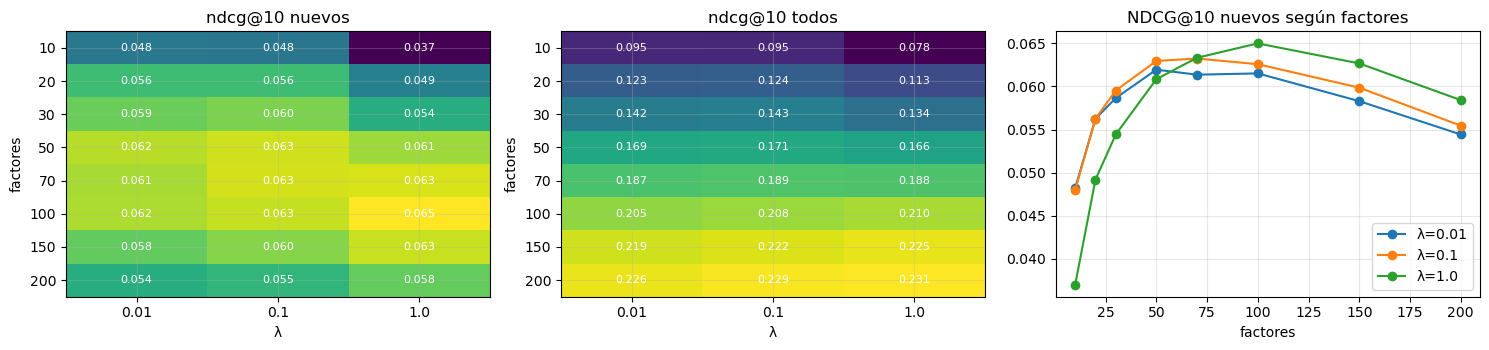

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for i, met in enumerate(["ndcg10_nuevos", "ndcg10_todos"]):
    t = grilla1.pivot(index="rank", columns="reg", values=met)
    ax[i].imshow(t, cmap="viridis", aspect="auto")
    ax[i].set(xticks=range(len(t.columns)), xticklabels=t.columns, yticks=range(len(t.index)), yticklabels=t.index,
              xlabel="λ", ylabel="factores", title=met.replace("10_", "@10 "))
    for (y, x), v in np.ndenumerate(t.to_numpy()):
        ax[i].text(x, y, f"{v:.3f}", ha="center", va="center", color="w", fontsize=8)
for reg, g in grilla1.groupby("reg"):
    ax[2].plot(g["rank"], g.ndcg10_nuevos, "o-", label=f"λ={reg}")
ax[2].set(title="NDCG@10 nuevos según factores", xlabel="factores"); ax[2].legend()
mostrar_fig("als_grilla_rank_reg")

In [12]:
mejor1 = grilla1.sort_values("ndcg10_nuevos", ascending=False).iloc[0]
por_rank = grilla1.groupby("rank").ndcg10_nuevos.max()
borde = int(mejor1["rank"]) == max(RANGO_RANK)
display(Markdown(
    f"- NDCG@10 nuevos va de **{grilla1.ndcg10_nuevos.min():.3f}** a **{grilla1.ndcg10_nuevos.max():.3f}**; "
    f"mejor: **{int(mejor1['rank'])} factores, λ = {mejor1.reg}**\n"
    f"- Mejor NDCG por n.º de factores: " + ", ".join(f"{r}: {v:.3f}" for r, v in por_rank.items()) + "\n"
    + ("- ⚠ **El óptimo sigue en el borde de la grilla**: habría que probar más factores\n" if borde else
       f"- **El óptimo está dentro de la grilla**: con {max(RANGO_RANK)} factores ya no mejora ({por_rank.iloc[-1]:.3f})\n")
    + f"- λ = 1.0 es el peor en {int((grilla1.loc[grilla1.groupby('rank').ndcg10_nuevos.idxmin(), 'reg'] == 1.0).sum())} de {len(RANGO_RANK)} tamaños"))

- NDCG@10 nuevos va de **0.037** a **0.065**; mejor: **100 factores, λ = 1.0**
- Mejor NDCG por n.º de factores: 10: 0.048, 20: 0.056, 30: 0.060, 50: 0.063, 70: 0.063, 100: 0.065, 150: 0.063, 200: 0.058
- **El óptimo está dentro de la grilla**: con 200 factores ya no mejora (0.058)
- λ = 1.0 es el peor en 4 de 8 tamaños

#### b. Grilla, etapa 2: α × señal

Con los mejores factores y λ de la etapa 1, se varían la confianza α y la señal (`r_frec`: solo frecuencia; `r_mix`: frecuencia + monto winsorizado)

In [13]:
for alpha in RANGO_ALPHA:
    for col in ["r_frec", "r_mix"]:
        U, V, seg = ajustar_als("ajuste", int(mejor1["rank"]), float(mejor1.reg), alpha, col)
        n_nue, n_tod, rec_nue = ndcg10("ajuste", candidatos_als("ajuste", U, V, n=50))
        grilla.append({"etapa": 2, "rank": int(mejor1["rank"]), "reg": float(mejor1.reg), "alpha": alpha, "senal": col,
                       "ndcg10_nuevos": n_nue, "ndcg10_todos": n_tod, "recall10_nuevos": rec_nue, "seg": seg})
grilla = pd.DataFrame(grilla)
grilla2 = grilla[grilla.etapa == 2]
grilla2.round(4)

,etapa,rank,reg,alpha,senal,ndcg10_nuevos,ndcg10_todos,recall10_nuevos,seg
24,2,100,1.0,1,r_frec,0.0116,0.0440,0.0046,21.2
25,2,100,1.0,1,r_mix,0.0218,0.0660,0.0096,20.3
26,2,100,1.0,10,r_frec,0.0650,0.2105,0.0401,20.1
27,2,100,1.0,10,r_mix,0.0650,0.2247,0.0408,20.2
28,2,100,1.0,40,r_frec,0.0605,0.2421,0.0368,20.4
29,2,100,1.0,40,r_mix,0.0516,0.2394,0.0316,20.3


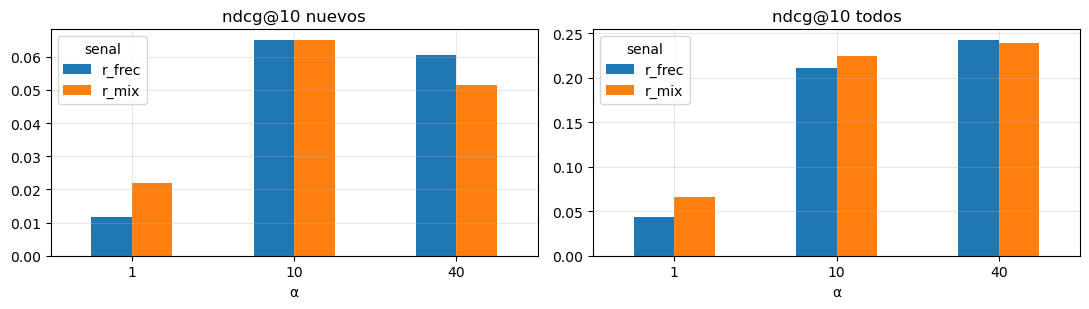

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, met in enumerate(["ndcg10_nuevos", "ndcg10_todos"]):
    grilla2.pivot(index="alpha", columns="senal", values=met).plot.bar(ax=ax[i], rot=0)
    ax[i].set(title=met.replace("10_", "@10 "), xlabel="α")
mostrar_fig("als_grilla_alpha_senal")

In [15]:
g2 = grilla2.set_index(["alpha", "senal"])
mejor2 = grilla2.sort_values("ndcg10_nuevos", ascending=False).iloc[0]
a_max = max(RANGO_ALPHA)
display(Markdown(
    f"- Mejor en nuevos: **α = {mejor2.alpha:g}, señal `{mejor2.senal}`** (NDCG@10 {mejor2.ndcg10_nuevos:.3f})\n"
    f"- Con α = {a_max} y `r_frec`: NDCG@10 todos = {g2.loc[(a_max, 'r_frec'), 'ndcg10_todos']:.3f} vs. "
    f"{g2.loc[(mejor2.alpha, mejor2.senal), 'ndcg10_todos']:.3f} del elegido; en nuevos {g2.loc[(a_max, 'r_frec'), 'ndcg10_nuevos']:.3f}: "
    "más confianza refuerza las relaciones existentes más que los sustitutos\n"
    f"- Monto (`r_mix`) vs. frecuencia (`r_frec`), promedio sobre α: todos "
    f"{grilla2.groupby('senal').ndcg10_todos.mean().diff().iloc[-1]:+.3f}, nuevos "
    f"{grilla2.groupby('senal').ndcg10_nuevos.mean().diff().iloc[-1]:+.3f}"))

- Mejor en nuevos: **α = 10, señal `r_mix`** (NDCG@10 0.065)
- Con α = 40 y `r_frec`: NDCG@10 todos = 0.242 vs. 0.225 del elegido; en nuevos 0.060: más confianza refuerza las relaciones existentes más que los sustitutos
- Monto (`r_mix`) vs. frecuencia (`r_frec`), promedio sobre α: todos +0.011, nuevos +0.000

#### c. Estabilidad entre semillas

- ALS parte de factores aleatorios: la diferencia entre las dos mejores configuraciones debe ser mayor que la variación por semilla

- Se repiten las 2 mejores configuraciones con `SEMILLAS` en el split ajuste

In [16]:
top2 = grilla.sort_values("ndcg10_nuevos", ascending=False).drop_duplicates(["rank", "reg", "alpha", "senal"]).head(2)
semillas = []
for _, r in top2.iterrows():
    for sd in SEMILLAS:
        U, V, _ = ajustar_als("ajuste", int(r["rank"]), float(r.reg), float(r.alpha), r.senal, seed=sd)
        n_nue, n_tod, _ = ndcg10("ajuste", candidatos_als("ajuste", U, V, n=50))
        semillas.append({"config": f"{int(r['rank'])}f λ={r.reg} α={r.alpha:g} {r.senal}", "rank": int(r["rank"]), "reg": float(r.reg),
                         "alpha": float(r.alpha), "senal": r.senal, "seed": sd, "ndcg10_nuevos": n_nue, "ndcg10_todos": n_tod})
semillas = pd.DataFrame(semillas)
estab = semillas.groupby("config", sort=False).ndcg10_nuevos.agg(["mean", "std", "min", "max"]).round(4)
estab

,mean,std,min,max
config,,,,
100f λ=1.0 α=10 r_mix,0.0645,0.0009,0.0634,0.0653
100f λ=1.0 α=10 r_frec,0.0641,0.0008,0.0631,0.0650


In [17]:
m = estab["mean"].to_numpy(); sd = estab["std"].max()
separadas = abs(m[0] - m[1]) > 2 * sd
mejor = semillas.groupby(["rank", "reg", "alpha", "senal"]).ndcg10_nuevos.mean().idxmax()
ALS_PARAMS = {"rank": int(mejor[0]), "reg": float(mejor[1]), "alpha": float(mejor[2]), "senal": mejor[3]}
display(Markdown(
    f"- Desviación entre semillas: hasta **{sd:.4f}**; diferencia entre las dos mejores configuraciones: **{abs(m[0] - m[1]):.4f}**\n"
    + ("- La diferencia supera 2σ: la elección **no es ruido de inicialización**\n" if separadas else
       "- La diferencia **no supera 2σ**: ambas configuraciones son equivalentes; se elige la de mayor media entre semillas\n")
    + f"- Configuración final: **{ALS_PARAMS['rank']} factores, λ = {ALS_PARAMS['reg']}, α = {ALS_PARAMS['alpha']:g}, señal `{ALS_PARAMS['senal']}`**"))
config = leer_config(); config["als"] = ALS_PARAMS; guardar_config(config)

- Desviación entre semillas: hasta **0.0009**; diferencia entre las dos mejores configuraciones: **0.0004**
- La diferencia **no supera 2σ**: ambas configuraciones son equivalentes; se elige la de mayor media entre semillas
- Configuración final: **100 factores, λ = 1.0, α = 10, señal `r_mix`**

---
### **3. Evaluación en el hold-out 2025**

- ALS se reentrena con 2023-2024 y los parámetros elegidos en ajuste

- Se guardan también los candidatos del split ajuste con esos parámetros: el peso `w` del híbrido se calibra ahí

- ALS se ajusta con las 5 `SEMILLAS` en el split final: se reporta media ± desviación; los candidatos guardados son los de `SEED`

In [18]:
cand_als = {}
for s in SPLITS:
    U, V, seg = ajustar_als(s, ALS_PARAMS["rank"], ALS_PARAMS["reg"], ALS_PARAMS["alpha"], ALS_PARAMS["senal"])
    cand_als[s] = candidatos_als(s, U, V)
    print(f"{s}: ALS en {seg} s")

c = ctx["final"]
res = []
for nombre in ["popularidad_global", "popularidad_familia"]:
    res += evaluar_modelo(c, nombre, base[("final", nombre)], universos=("completo", "alcanzable"), conocidos=c.ganadores)
res += evaluar_modelo(c, "als", cand_als["final"], universos=("completo", "alcanzable"), conocidos=c.ganadores)
res = pd.DataFrame(res)
cols = ["modelo", "precision", "recall", "ndcg", "map", "cobertura", "pct_cola_larga", "pct_no_ganadores", "popularidad_media"]

ajuste: ALS en 22.7 s


final: ALS en 39.6 s


In [19]:
sem_final = []
for sd in SEMILLAS:
    U, V, _ = ajustar_als("final", ALS_PARAMS["rank"], ALS_PARAMS["reg"], ALS_PARAMS["alpha"], ALS_PARAMS["senal"], seed=sd)
    r = pd.DataFrame(evaluar_modelo(c, "als", candidatos_als("final", U, V, n=50)))
    sem_final += r[r.grupo == "todas"].assign(seed=sd).to_dict("records")
sem_final = pd.DataFrame(sem_final)
var_semilla = sem_final.groupby(["regimen", "k"])[["ndcg", "recall", "map"]].agg(["mean", "std"]).round(4)
var_semilla

ndcg          recall             map        
              mean     std    mean     std    mean     std
regimen k                                                 
nuevos  5   0.0601  0.0006  0.0278  0.0008  0.0336  0.0004
        10  0.0562  0.0002  0.0395  0.0005  0.0256  0.0001
todos   5   0.2378  0.0007  0.0910  0.0005  0.1588  0.0005
        10  0.2140  0.0004  0.1231  0.0006  0.1217  0.0003

#### a. Todas las entidades

In [20]:
for reg in ["nuevos", "todos"]:
    for k in KS:
        print(f"régimen {reg}, K = {k}")
        display(res[(res.regimen == reg) & (res.grupo == "todas") & (res.universo == "completo") & (res.k == k)][cols].round(4))

régimen nuevos, K = 5


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
8,popularidad_global,0.0149,0.0072,0.0170,0.0089,0.0001,0.0000,0.0,155.7251
24,popularidad_familia,0.0231,0.0092,0.0274,0.0152,0.0046,0.0151,0.0,52.6790
40,als,0.0506,0.0286,0.0601,0.0335,0.0120,0.0130,0.0,30.6057


régimen nuevos, K = 10


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
9,popularidad_global,0.0127,0.0116,0.0171,0.0072,0.0001,0.0000,0.0,126.8135
25,popularidad_familia,0.0186,0.0137,0.0249,0.0107,0.0085,0.0191,0.0,42.3981
41,als,0.0388,0.0392,0.0560,0.0256,0.0197,0.0224,0.0,26.1336


régimen todos, K = 5


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
0,popularidad_global,0.0326,0.0101,0.0394,0.0218,0.0000,0.0000,0.0,159.2000
16,popularidad_familia,0.0724,0.0229,0.0845,0.0525,0.0041,0.0150,0.0,59.3355
32,als,0.2031,0.0915,0.2377,0.1587,0.0133,0.0242,0.0,32.3424


régimen todos, K = 10


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
1,popularidad_global,0.0287,0.0160,0.0369,0.0156,0.0001,0.0000,0.0,130.0000
17,popularidad_familia,0.0543,0.0320,0.0721,0.0360,0.0077,0.0190,0.0,46.9996
33,als,0.1558,0.1232,0.2141,0.1218,0.0244,0.0471,0.0,27.0874


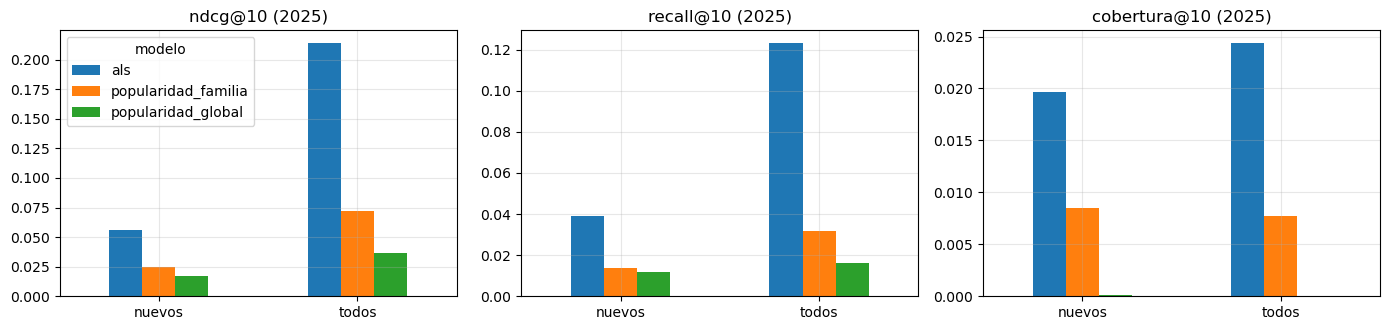

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
q = res[(res.grupo == "todas") & (res.universo == "completo") & (res.k == 10)]
for i, met in enumerate(["ndcg", "recall", "cobertura"]):
    q.pivot(index="regimen", columns="modelo", values=met).plot.bar(ax=ax[i], rot=0, legend=(i == 0))
    ax[i].set(title=f"{met}@10 (2025)", xlabel="")
mostrar_fig("final_comparacion")

#### b. Intervalos de confianza (bootstrap por entidad)

- NDCG@10 de cada modelo con IC 95%, y la **diferencia pareada** de ALS contra la mejor línea base

In [22]:
recs_f = {(m, reg): a_recs(cd[reg]) for m, cd in [("popularidad_global", base[("final", "popularidad_global")]),
                                                  ("popularidad_familia", base[("final", "popularidad_familia")]),
                                                  ("als", cand_als["final"])] for reg in ["todos", "nuevos"]}
ic = []
for reg in ["nuevos", "todos"]:
    v = {m: por_entidad(recs_f[(m, reg)], c.verdad[reg], 10) for m in ["popularidad_global", "popularidad_familia", "als"]}
    mejor_base = max(["popularidad_global", "popularidad_familia"], key=lambda m: v[m].mean())
    for m in v:
        ic.append({"regimen": reg, "comparacion": m, **dict(zip(["media", "ic_inf", "ic_sup"], ic_bootstrap(v[m])))})
    ic.append({"regimen": reg, "comparacion": f"als − {mejor_base}", **dict(zip(["media", "ic_inf", "ic_sup"], ic_bootstrap(v["als"], v[mejor_base])))})
ic = pd.DataFrame(ic).round(4)
ic

,regimen,comparacion,media,ic_inf,ic_sup
0,nuevos,popularidad_global,0.0171,0.0148,0.0197
1,nuevos,popularidad_familia,0.0249,0.0219,0.0279
2,nuevos,als,0.0560,0.0519,0.0606
3,nuevos,als − popularidad_familia,0.0311,0.0269,0.0356
4,todos,popularidad_global,0.0369,0.0336,0.0401
5,todos,popularidad_familia,0.0721,0.0667,0.0778
6,todos,als,0.2141,0.2055,0.2221
7,todos,als − popularidad_familia,0.1420,0.1351,0.1492


In [23]:
q = res[(res.grupo == "todas") & (res.universo == "completo") & (res.k == 10)].set_index(["regimen", "modelo"])
d = ic[ic.comparacion.str.startswith("als −")].set_index("regimen")
fam_vs_glob = {reg: q.loc[(reg, "popularidad_familia"), "ndcg"] - q.loc[(reg, "popularidad_global"), "ndcg"] for reg in ["nuevos", "todos"]}
display(Markdown("\n".join(
    [f"- **{reg}:** ALS NDCG@10 = {q.loc[(reg, 'als'), 'ndcg']:.3f} "
     f"(± {var_semilla.loc[(reg, 10), ('ndcg', 'std')]:.4f} entre semillas) vs. mejor línea base "
     f"{max(q.loc[(reg, 'popularidad_global'), 'ndcg'], q.loc[(reg, 'popularidad_familia'), 'ndcg']):.3f}; "
     f"diferencia {d.loc[reg, 'media']:+.3f}, IC 95% [{d.loc[reg, 'ic_inf']:+.3f}, {d.loc[reg, 'ic_sup']:+.3f}]"
     + (" → **significativa**" if d.loc[reg, "ic_inf"] > 0 else " → no significativa") for reg in ["nuevos", "todos"]]
    + [f"- Popularidad por familia − global: nuevos {fam_vs_glob['nuevos']:+.3f}, todos {fam_vs_glob['todos']:+.3f}"
       + (" (el rubro personaliza bien relaciones existentes, pero al excluir a los proveedores ya vistos pierde a los grandes de su rubro)"
          if fam_vs_glob["todos"] > 0 >= fam_vs_glob["nuevos"] else ""),
       f"- **Sesgo de popularidad:** cobertura de ALS = {q.loc[('nuevos', 'als'), 'cobertura']:.2%} del catálogo; "
       f"popularidad media de lo recomendado = {q.loc[('nuevos', 'als'), 'popularidad_media']:.0f} clientes",
       f"- **% no ganadores = {q.loc[('nuevos', 'als'), 'pct_no_ganadores']:.0%}** en los tres modelos, por construcción"])))

- **nuevos:** ALS NDCG@10 = 0.056 (± 0.0002 entre semillas) vs. mejor línea base 0.025; diferencia +0.031, IC 95% [+0.027, +0.036] → **significativa**
- **todos:** ALS NDCG@10 = 0.214 (± 0.0004 entre semillas) vs. mejor línea base 0.072; diferencia +0.142, IC 95% [+0.135, +0.149] → **significativa**
- Popularidad por familia − global: nuevos +0.008, todos +0.035
- **Sesgo de popularidad:** cobertura de ALS = 1.97% del catálogo; popularidad media de lo recomendado = 26 clientes
- **% no ganadores = 0%** en los tres modelos, por construcción

#### c. Techo de *cold-start*

Recall con la verdad completa vs. restringida a proveedores que ganaron en train (los únicos que estos modelos pueden recomendar)

In [24]:
techo = (res[(res.grupo == "todas") & (res.k == 10)]
         .pivot_table(index=["modelo", "regimen"], columns="universo", values="recall").round(4))
t = techo.loc[("als", "nuevos")]
display(techo)
display(Markdown(
    f"- En pares nuevos, ALS recupera el **{t.alcanzable:.1%}** de lo que puede alcanzar, pero el **{t.completo:.1%}** del total\n"
    f"- Una parte grande de la brecha es *cold-start*, no error del modelo: el contenido debe ampliar el **universo alcanzable**, no solo reordenar"))

universo                     alcanzable  completo
modelo              regimen                      
als                 nuevos       0.1173    0.0392
                    todos        0.2844    0.1232
popularidad_familia nuevos       0.0370    0.0137
                    todos        0.0657    0.0320
popularidad_global  nuevos       0.0307    0.0116
                    todos        0.0312    0.0160

- En pares nuevos, ALS recupera el **11.7%** de lo que puede alcanzar, pero el **3.9%** del total
- Una parte grande de la brecha es *cold-start*, no error del modelo: el contenido debe ampliar el **universo alcanzable**, no solo reordenar

#### d. Entidades cautivas (PQ3.1)

In [25]:
caut = res[(res.regimen == "nuevos") & (res.universo == "completo") & (res.k == 10)].pivot_table(
    index="modelo", columns="grupo", values=["ndcg", "recall"]).round(4)
display(caut)
a = caut.loc["als"]
display(Markdown(
    f"- En entidades cautivas, ALS encuentra sustitutos reales del año de test con NDCG@10 = **{a[('ndcg', 'cautivas')]:.3f}** "
    f"y recall@10 = **{a[('recall', 'cautivas')]:.3f}** (todas: {a[('ndcg', 'todas')]:.3f} y {a[('recall', 'todas')]:.3f})\n"
    "- Los casos concretos (GR Loreto, postor único) se analizan en `e_analisis_sustitutos`"))

ndcg           recall        
grupo               cautivas   todas cautivas   todas
modelo                                               
als                   0.0419  0.0560   0.0418  0.0392
popularidad_familia   0.0128  0.0249   0.0120  0.0137
popularidad_global    0.0138  0.0171   0.0145  0.0116

- En entidades cautivas, ALS encuentra sustitutos reales del año de test con NDCG@10 = **0.042** y recall@10 = **0.042** (todas: 0.056 y 0.039)
- Los casos concretos (GR Loreto, postor único) se analizan en `e_analisis_sustitutos`

---
### **4. Escritura de datos**

- `temp/datos/<split>_cand_als`: top-`N_CAND` de ALS por entidad y régimen (entrada del híbrido)

- `temp/datos/<split>_cand_<línea base>`: ídem para las líneas base

In [26]:
def guardar_cand(cand, nombre):
    pd.concat([df.assign(regimen=reg) for reg, df in cand.items()]).to_parquet(datos_dir / nombre, index=False)

for s in SPLITS:
    guardar_cand(cand_als[s], f"{s}_cand_als")
    for nombre in ["popularidad_global", "popularidad_familia"]:
        guardar_cand(base[(s, nombre)], f"{s}_cand_{nombre}")

#### a. Verificación

- Candidatos sin duplicados por entidad y régimen

- En régimen `nuevos` ningún candidato fue proveedor de la entidad en train

In [27]:
for s in SPLITS:
    c = ctx[s]
    for nombre in ["als", "popularidad_global", "popularidad_familia"]:
        d = pd.read_parquet(datos_dir / f"{s}_cand_{nombre}")
        assert not d.duplicated(["regimen", "entidad_key", "proveedor_key"]).any(), (s, nombre)
        nue = d[d.regimen == "nuevos"]
        assert not any(p in c.vistos_key.get(u, ()) for u, p in zip(nue.entidad_key, nue.proveedor_key)), (s, nombre)
        assert d.groupby(["regimen", "entidad_key"]).size().max() <= N_CAND
    print(f"{s}: OK")

ajuste: OK


final: OK


### **5. Escritura de resultados**

In [28]:
escritos = guardar_tablas({"grilla_als": grilla, "semillas_ajuste": semillas, "semillas_final": sem_final,
                           "evaluacion_final": res, "ic_bootstrap": ic, "techo_cold_start": techo.reset_index(),
                           "parametros_als": pd.DataFrame([ALS_PARAMS])})

Escrito en 03_Recomendacion/temp/b_baseline_als/: grilla_als, semillas_ajuste, semillas_final, evaluacion_final, ic_bootstrap, techo_cold_start, parametros_als


#### a. Verificación

In [29]:
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 3 figuras: als_grilla_alpha_senal, als_grilla_rank_reg, final_comparacion


---
### **6. Cerrar sesión**

In [30]:
spark.stop()